In [1]:
import warnings
import pandas as pd
import plotly.express as px
from data import *

warnings.filterwarnings("ignore")
pd.set_option('display.max_rows', None)

ts_user = 'KBa'
gitlab_user = 'konrad.baczynski'

:: loading settings :: url = jar:file:/home/daniel.las/work/workspace-crypto/oda/notebooks/venv/lib/python3.8/site-packages/pyspark/jars/ivy-2.5.0.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/daniel.las/.ivy2/cache
The jars for the packages stored in: /home/daniel.las/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
org.apache.spark#spark-avro_2.12 added as a dependency
org.postgresql#postgresql added as a dependency
com.github.jnr#jnr-posix added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-c91884d3-385f-4e15-bc6f-9521540c90a9;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.2.0 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.2.0 in central
	found com.datastax.oss#java-driver-core-shaded;4.13.0 in central
	found com.datastax.oss#native-protocol;1.5.0 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in local-m2-cache
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhist

# KBa

In [2]:
user_issues(ts_user).toPandas()

,key,summary,status,type,priority,size,size_points,status_changed_at,issue_total_hours,user_total_hours
0,CRYP-10863,Shift analyser nie generuje danych,Done,Bug,Highest,?,None,2025-07-15 06:24:02.960,13.5,7.5
1,CRYP-10797,[BingX] Trade z qty 0,Delivery,Bug,Medium,?,None,2025-07-14 08:23:37.271,4.5,3.5
2,CRYP-10816,[Backtest] celo-usdt-e-binancefts ended with s...,Delivery,Bug,High,XS,1,2025-07-10 13:03:47.621,10.0,3.0
3,CRYP-10843,Weryfikacja poprawności konfiguracji mdr-coeff...,Delivered,Story,Medium,?,None,2025-07-10 08:03:06.364,6.0,4.5
4,CRYP-10860,Przepisanie Shift analyser na Javę,In Progress,Story,Medium,?,None,2025-07-10 07:49:16.097,19.0,19.0
5,CRYP-10842,[Bitkub] Przeterminowany coefficient w MARKET_...,Delivery,Bug,High,?,None,2025-07-08 11:31:51.015,10.5,7.0
6,CRYP-10083,Odświeżanie subskrypcji MDR w Platform Admin p...,In Review,Sub-task,Medium,?,None,2025-07-08 08:32:01.732,7.5,1.0
7,CRYP-10841,[Kraken] Brak cyklicznej emisji SECURITY_DEFIN...,Delivery,Bug,Medium,?,None,2025-07-08 07:20:29.685,5.0,4.0
8,CRYP-10777,Duplikaty w hurtowni w security_definition_v1,Delivered,Bug,Medium,?,None,2025-07-07 11:00:03.145,16.0,13.5
9,CRYP-10658,[Liquidty Calculator] Wartości pól w różnych o...,Delivery,Bug,High,?,None,2025-07-07 10:54:21.899,138.5,69.5


In [3]:
user_issues_hours_monthly(ts_user).toPandas()

,month,jira_id,summary,status,hours
0,2025-07-01,CRYP-10658,[Liquidty Calculator] Wartości pól w różnych o...,Delivery,8.5
1,2025-07-01,CRYP-10777,Duplikaty w hurtowni w security_definition_v1,Delivered,3.5
2,2025-07-01,CRYP-10836,Rozszerzenie statusów na potrzeby informowania...,In Progress,33.5
3,2025-07-01,CRYP-10842,[Bitkub] Przeterminowany coefficient w MARKET_...,Delivery,1.0
4,2025-07-01,CRYP-10843,Weryfikacja poprawności konfiguracji mdr-coeff...,Delivered,4.5
5,2025-07-01,CRYP-10860,Przepisanie Shift analyser na Javę,In Progress,19.0
6,2025-07-01,CRYP-10863,Shift analyser nie generuje danych,Done,7.5
7,2025-06-01,CRYP-10083,Odświeżanie subskrypcji MDR w Platform Admin p...,In Review,1.0
8,2025-06-01,CRYP-10658,[Liquidty Calculator] Wartości pól w różnych o...,Delivery,9.5
9,2025-06-01,CRYP-10658,[Liquidty Calculator] Wartości pól w różnych o...,Delivery,4.5


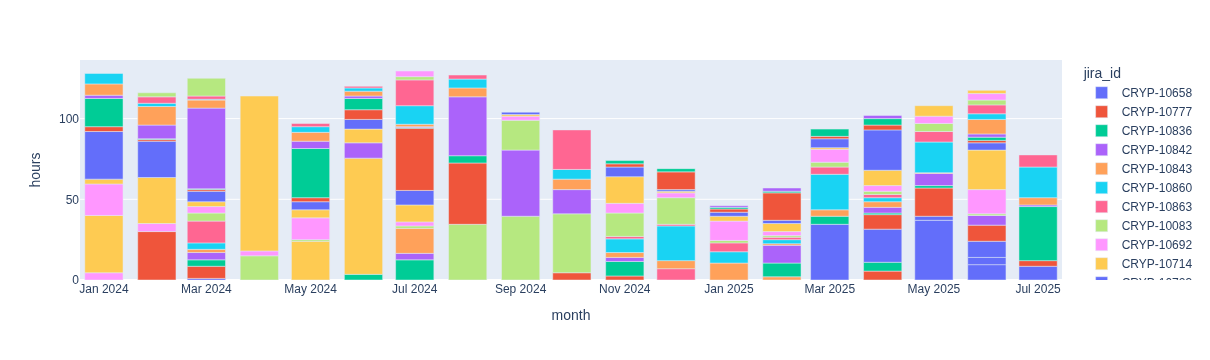

In [4]:
px.bar(user_issues_hours_monthly(ts_user).toPandas(),x='month',y='hours',color='jira_id',hover_data={'summary':True})

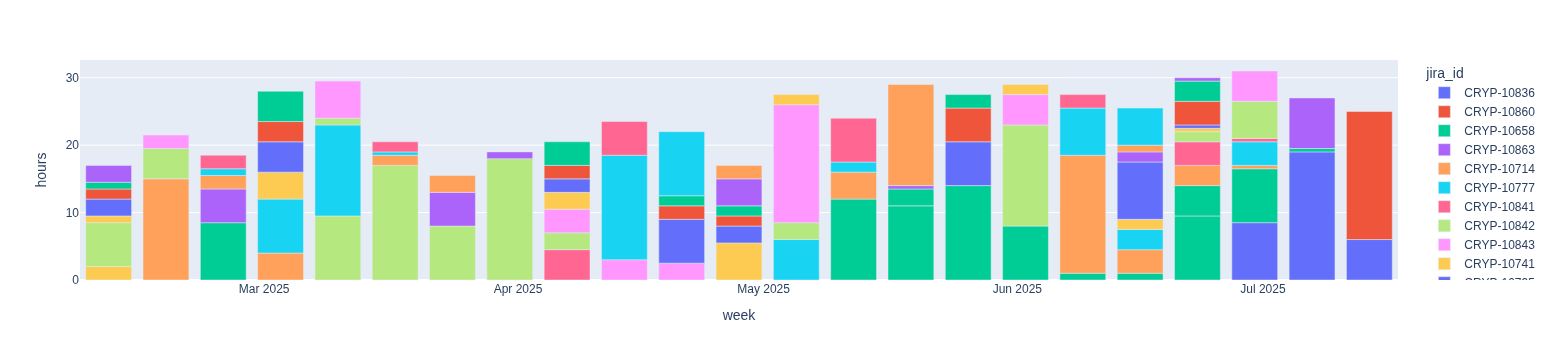

In [10]:
px.bar(user_issues_hours_weekly(ts_user).toPandas(),x='week',y='hours',color='jira_id',hover_data={'summary':True})

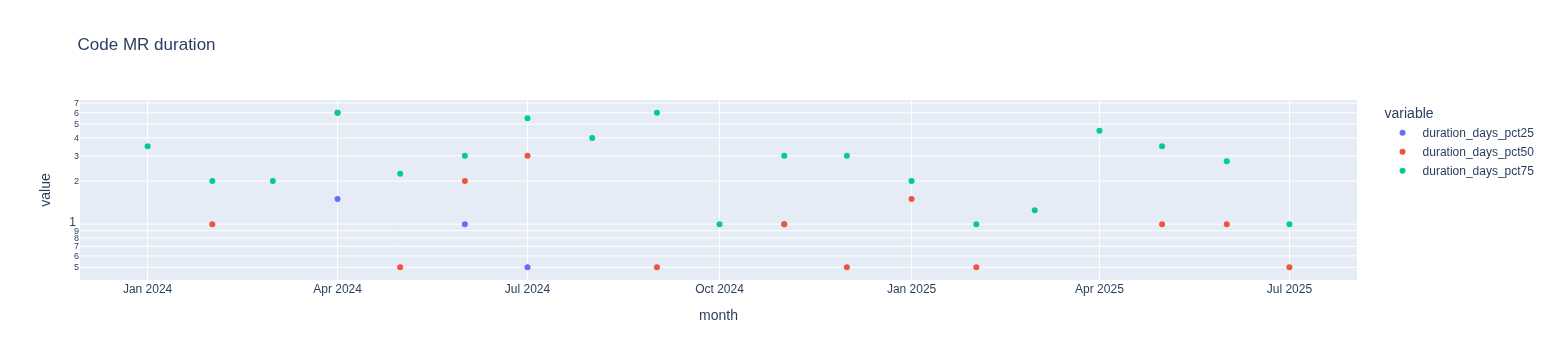

In [11]:
px.scatter(user_mrs_duration(gitlab_user).toPandas(),x='month',y=['duration_days_pct25','duration_days_pct50','duration_days_pct75'], log_y=True,title='Code MR duration')

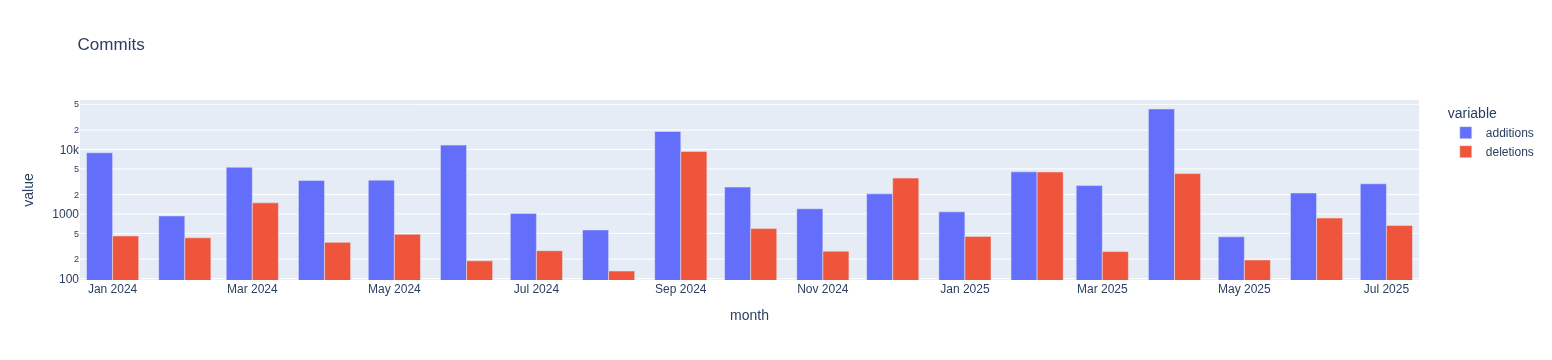

In [12]:
px.bar(user_code_commits(gitlab_user).toPandas(),x='month',y=['additions','deletions'],log_y=True,title='Commits',barmode='group')

In [8]:
users_hours.where(f.col('user')==ts_user).toPandas()

,month,user,jira_hours,other_hours,total_hours,other_hours_pct
0,2025-07-01,KBa,77.5,33.5,111.0,30.180180
1,2025-06-01,KBa,117.5,42.5,160.0,26.562500
2,2025-05-01,KBa,108.0,54.0,162.0,33.333333
3,2025-04-01,KBa,102.0,68.0,170.0,40.000000
4,2025-03-01,KBa,93.5,66.5,160.0,41.562500
5,2025-02-01,KBa,57.0,48.0,105.0,45.714286
6,2025-01-01,KBa,46.0,42.0,88.0,47.727273
7,2024-12-01,KBa,69.0,75.0,144.0,52.083333
8,2024-11-01,KBa,74.0,70.0,144.0,48.611111
9,2024-10-01,KBa,93.0,84.0,177.0,47.457627


In [9]:
user_other_hours(ts_user).toPandas()

,month,task_desc,other_hours
0,2025-07-01,Spotkania projektowe,10.5
1,2025-07-01,1:1,1.0
2,2025-07-01,Release Manager,9.5
3,2025-07-01,Code review,5.5
4,2025-07-01,Konsultacje z zespołem dev,3.5
5,2025-07-01,Konsultacje z zespołem testerskim,1.0
6,2025-07-01,Konsultacje z zespołem data science,0.5
7,2025-07-01,Konsultacje z zespołem devops,0.5
8,2025-07-01,Wsparcie produkcji liquee,1.5
9,2025-06-01,Release Manager,10.0
